# Setup

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from src.constants import DATASETS_DIR
from src.data_loading import load_csv_data, parse_preprocessing_config
from src.dataset_config import load_dataset_config
from src.preprocessing import filter_doublets, normalize_by_library_size, log_transform, normalize_with_pearson
from src.preprocessing.gene_annotation import load_gene_annotation
from src.preprocessing.gene_sets import duplicated_genes, matching_genes, rrna_genes, unmatched_genes
from src.preprocessing.pipeline import run_filtering_pipeline
from src.preprocessing.qc_metrics import cell_qc_metrics
from src.visualization import (
    plot_qc_overview,
    plot_gene_set_qc,
    plot_gene_max_count_distribution,
    plot_normalization_comparison,
    plot_log_transform_comparison,
)

## Data Loading

In [3]:
from src.data_loading import load_csv_data

DATA_PATH = DATASETS_DIR / 'GSE118767_celseq2_3cl' / 'interim' / 'counts.csv.gz'
raw_data = load_csv_data(DATA_PATH)

raw_data

,ENSG00000281131,ENSG00000227456,ENSG00000240767,ENSG00000284221,ENSG00000272472,ENSG00000213513,ENSG00000123500,ENSG00000127366,ENSG00000230601,ENSG00000260808,...,ENSG00000255850,ENSG00000197355,ENSG00000138617,ENSG00000229256,ENSG00000175224,ENSG00000166446,ENSG00000278783,ENSG00000279274,ENSG00000148143,ENSG00000226887
cell_id,,,,,,,,,,,,,,,,,,,,,
A1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A10,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,4,2,0,0,3,0
A11,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,2,1
A13,0,0,0,0,0,0,0,0,0,0,...,1,0,1,0,1,0,0,0,3,0
A14,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,4,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,5,1
P6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,2,0
P7,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,3,1,0,0,1,0


## Dataset config

In [4]:
DATASET_DIR = DATASETS_DIR / 'GSE118767_celseq2_3cl'

dataset_config = load_dataset_config(DATASET_DIR / 'config.yaml')
SPECIES = dataset_config["species"]
preprocessing_config = parse_preprocessing_config(dataset_config)

preprocessing_config

PreprocessingConfig(mito_threshold=0.3, min_gene_max_count=2, count_threshold=None, gene_threshold=None)

# Quality Control

In [5]:
qc_metrics = cell_qc_metrics(raw_data, species=SPECIES)

print(qc_metrics.median().round(3))
display(qc_metrics.head(5).round(3))
display(qc_metrics.tail(5).round(3))

count_depth           37300.500
n_genes                7547.000
mito_fraction             0.088
rrna_fraction             0.034
apoptosis_fraction        0.017
dtype: float64


,count_depth,n_genes,mito_fraction,rrna_fraction,apoptosis_fraction
cell_id,,,,,
P10,99428,10810,0.075,0.026,0.016
D18,97052,10593,0.077,0.029,0.019
N5,86119,10027,0.088,0.032,0.017
F7,81034,9655,0.091,0.033,0.015
C16,80860,9666,0.129,0.043,0.015


,count_depth,n_genes,mito_fraction,rrna_fraction,apoptosis_fraction
cell_id,,,,,
H12,11416,4184,0.036,0.016,0.026
H15,10053,3518,0.124,0.046,0.014
J19,9975,2823,0.254,0.072,0.012
I23,9280,3031,0.160,0.045,0.012
J7,8204,3238,0.058,0.021,0.013


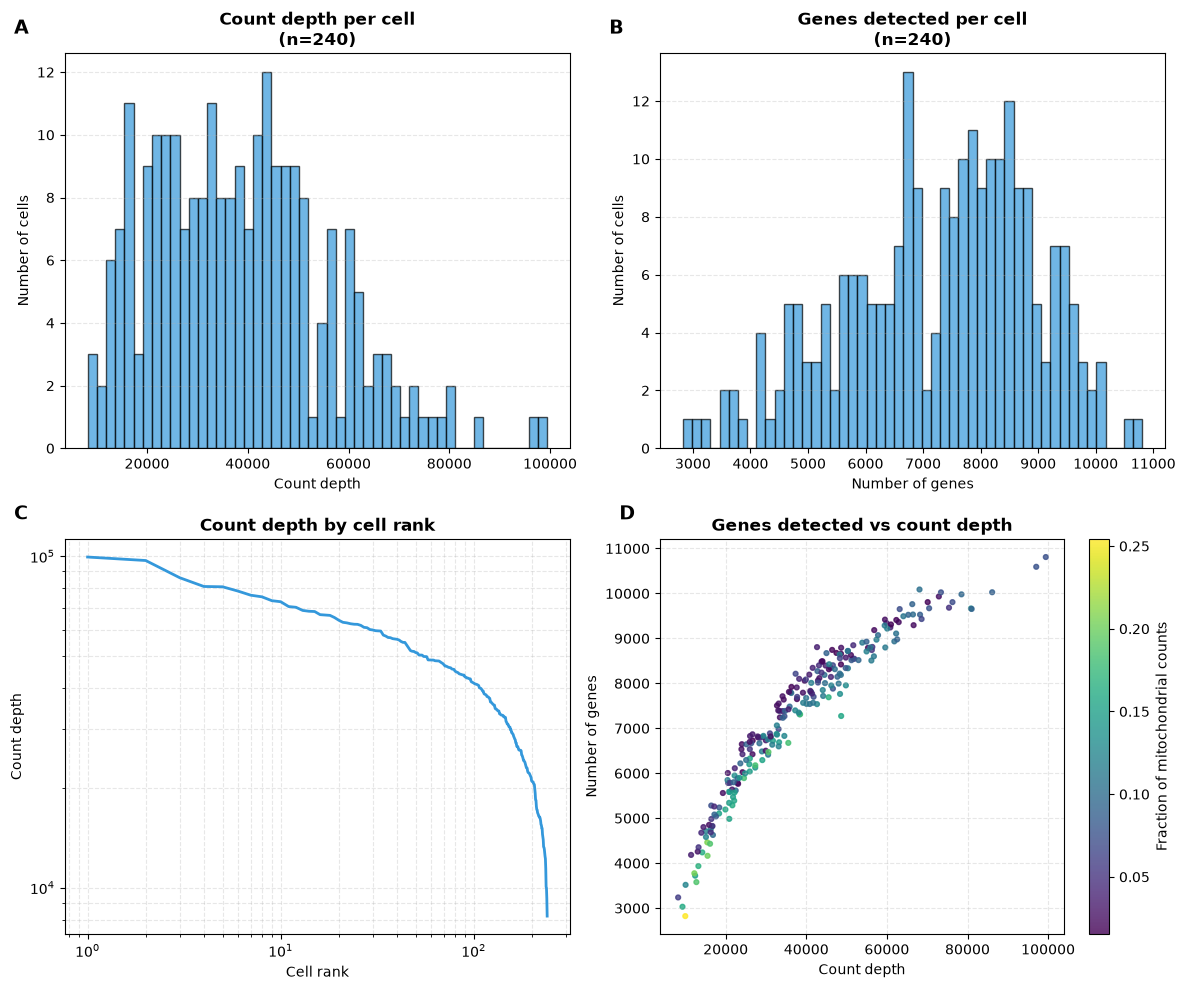

In [6]:
plot_qc_overview(
    raw_data,
    species=SPECIES,
    count_threshold=preprocessing_config.count_threshold,  # minimum count depth, set in the dataset config
    gene_threshold=preprocessing_config.gene_threshold,    # minimum genes per cell, set in the dataset config
)

## Mitochondrial, rRNA and apoptosis fractions

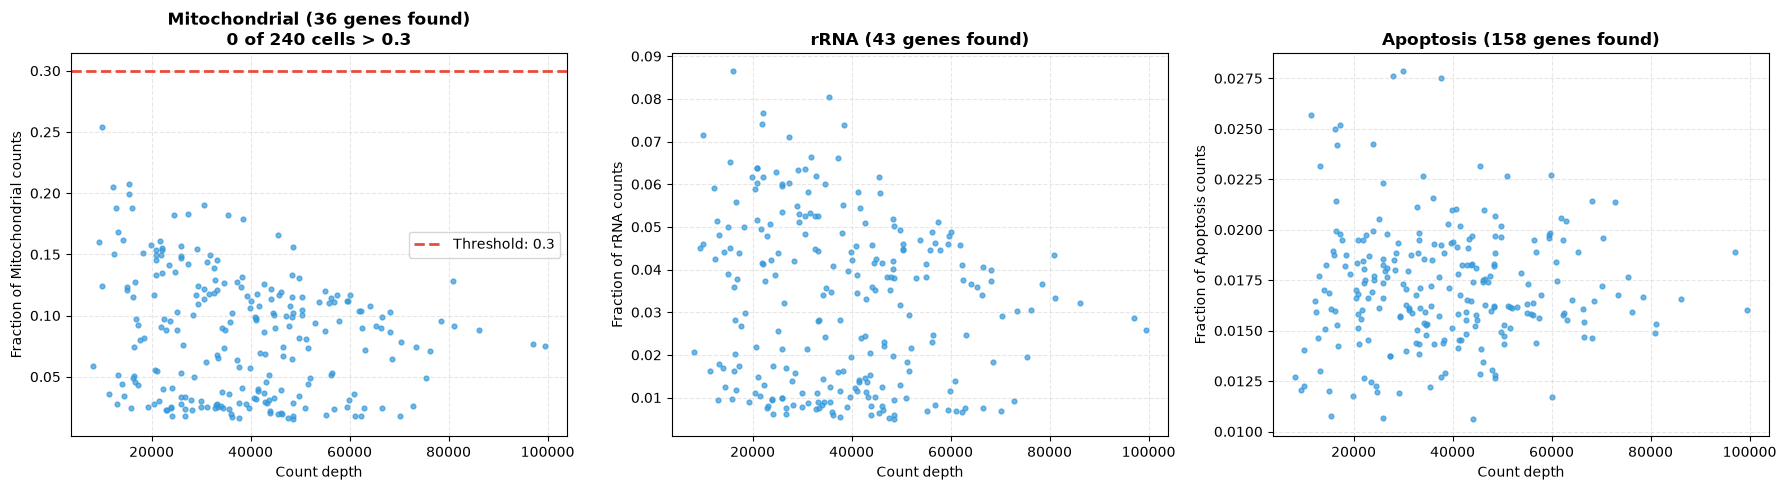

In [8]:
plot_gene_set_qc(raw_data, SPECIES, preprocessing_config)

## Genes

### Uniqueness

In [9]:
duplicates = duplicated_genes(raw_data)

print(f"Gene columns: {raw_data.shape[1]}, unique gene names: {raw_data.columns.nunique()}")
print(f"Gene names appearing in more than one column: {len(duplicates)}")
display(duplicates)

assert duplicates.empty, "Duplicated gene names found, see the table above"

Gene columns: 28142, unique gene names: 28142
Gene names appearing in more than one column: 0


,n_columns,identical_counts
gene,,


### Missing from the annotation

In [10]:
annotation = load_gene_annotation(SPECIES)
unmatched = unmatched_genes(raw_data, annotation)
alias_hits = unmatched.alias_matches
n_alias_genes = alias_hits["gene"].nunique()
n_ambiguous = alias_hits.loc[alias_hits["n_matches"] > 1, "gene"].nunique()

print(f"Genes matching no gene_id or gene_name: {n_alias_genes + len(unmatched.unknown_ensembl_ids) + len(unmatched.other)} / {raw_data.shape[1]}")
print(f"  found through alias_names: {n_alias_genes} ({n_ambiguous} matching more than one annotation row)")
print(f"  Ensembl IDs missing from the annotation: {len(unmatched.unknown_ensembl_ids)}, e.g. {unmatched.unknown_ensembl_ids[:5]}")
print(f"  other: {len(unmatched.other)}, e.g. {unmatched.other[:5]}")
display(alias_hits)

Genes matching no gene_id or gene_name: 581 / 28142
  found through alias_names: 0 (0 matching more than one annotation row)
  Ensembl IDs missing from the annotation: 581, e.g. ['ENSG00000231429', 'ENSG00000239674', 'ENSG00000262227', 'ENSG00000240929', 'ENSG00000275636']
  other: 0, e.g. []


,gene,n_matches,gene_id,gene_name,gene_biotype,chromosome,MT_status,RB_status,TF_status,APOPT_status,alias_names


### rRNA

In [11]:
# Same matching as filter_rrna_genes, so these are exactly the columns the pipeline drops
rrna_columns = matching_genes(raw_data, rrna_genes(SPECIES, annotation))
rrna_counts = raw_data[rrna_columns].sum().sort_values(ascending=False).rename("total_counts")

print(f"rRNA genes filtered out: {len(rrna_columns)} / {raw_data.shape[1]}")
print(f"  share of all counts: {rrna_counts.sum() / raw_data.values.sum():.3f}")
display(rrna_counts.to_frame())

rRNA genes filtered out: 43 / 28142
  share of all counts: 0.031


,total_counts
ENSG00000210082,250529
ENSG00000211459,34449
ENSG00000199804,19
ENSG00000252060,4
ENSG00000199874,4
ENSG00000202502,4
ENSG00000223138,3
ENSG00000251920,3
ENSG00000201185,3
ENSG00000278233,2


## Filtering pipeline

In [12]:
clean_data = run_filtering_pipeline(raw_data, config=preprocessing_config, species=SPECIES)

clean_data.shape

(240, 18567)

### Low expression genes

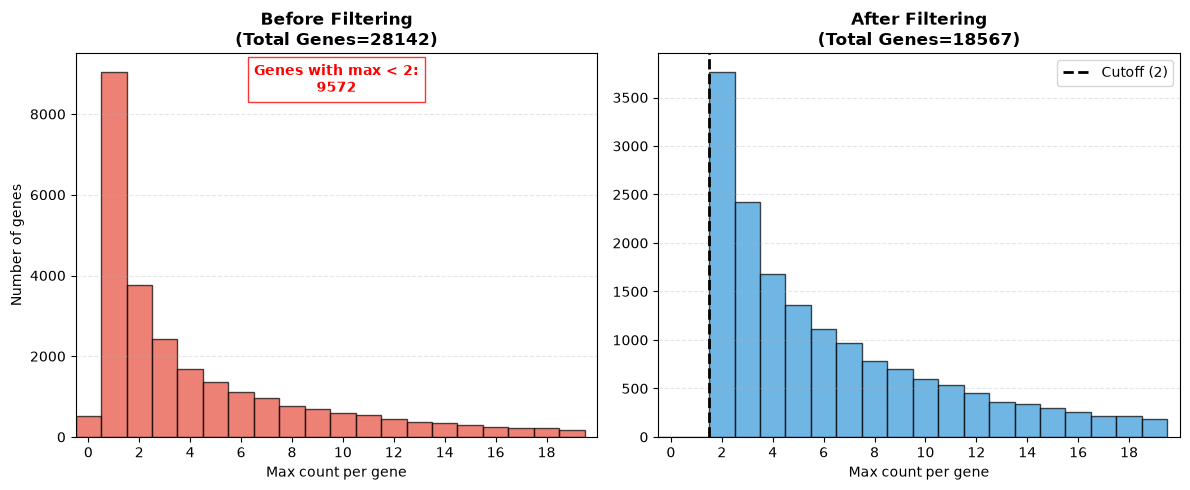

In [13]:
plot_gene_max_count_distribution(raw_data, clean_data, x_limit=20)

## Doublets (demonstration only)

We run the doublet filter to show how many cells it would remove, but the rest of the notebook continues from `clean_data`.

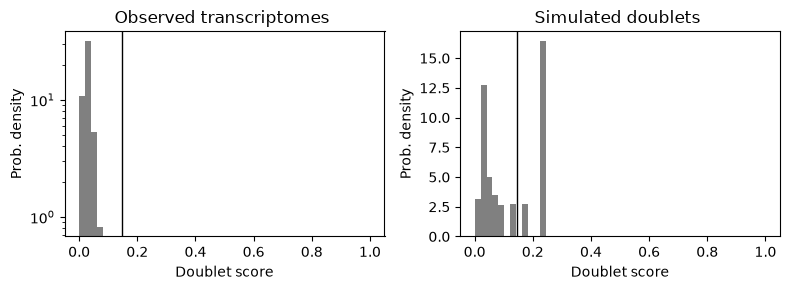

Cells removed as doublets: 0 / 240


In [14]:
# For demonstration only: the rest of the notebook continues from clean_data, not from no_doublets_data
no_doublets_data = filter_doublets(clean_data)

print(f"Cells removed as doublets: {clean_data.shape[0] - no_doublets_data.shape[0]} / {clean_data.shape[0]}")

# Normalization

## logCPM

### Normalize by library size

In [15]:
normalized_data = normalize_by_library_size(clean_data)

normalized_data.shape

(240, 18567)

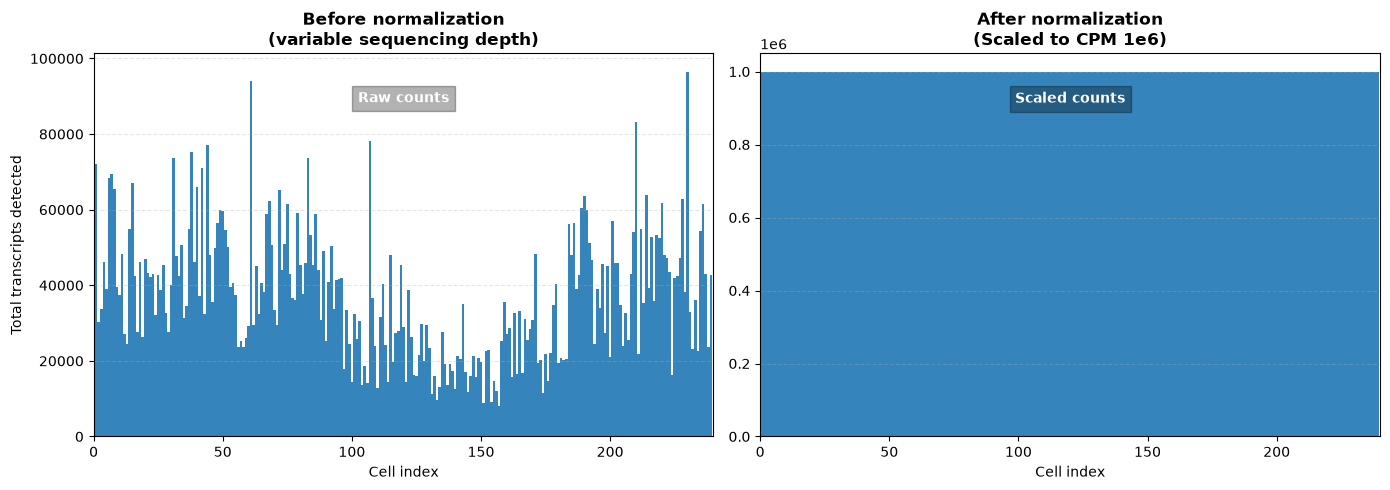

In [16]:
plot_normalization_comparison(clean_data, normalized_data, n_cells=normalized_data.shape[0])

### Log Transform

In [17]:
logged_data = log_transform(normalized_data)

logged_data.shape

(240, 18567)

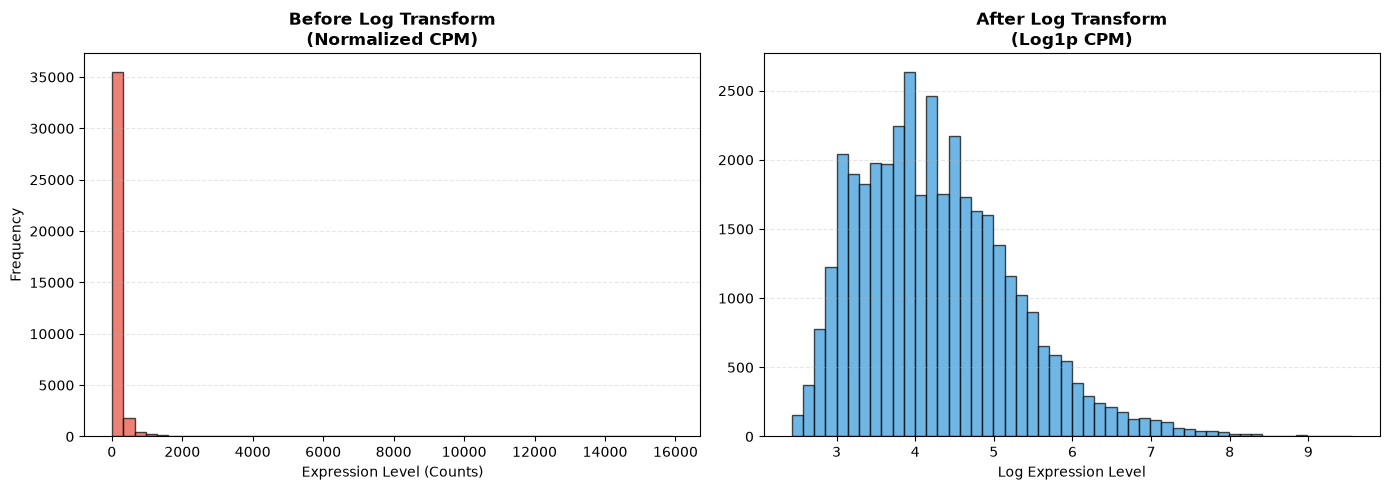

In [18]:
plot_log_transform_comparison(normalized_data, logged_data)

## Pearson residuals

In [19]:
pearsons_data = normalize_with_pearson(clean_data)

pearsons_data.shape

(240, 18567)

In [20]:
pearsons_data.head()

,ENSG00000227456,ENSG00000236086,ENSG00000233021,ENSG00000271259,ENSG00000248668,ENSG00000234323,ENSG00000261529,ENSG00000180287,ENSG00000223911,ENSG00000238055,...,ENSG00000060749,ENSG00000213090,ENSG00000135587,ENSG00000255850,ENSG00000197355,ENSG00000138617,ENSG00000175224,ENSG00000166446,ENSG00000148143,ENSG00000226887
cell_id,,,,,,,,,,,,,,,,,,,,,
A1,-0.059227,-0.059227,-0.059227,-0.102581,-0.059227,-0.059227,-0.059227,-0.059227,-0.072537,-0.059227,...,-1.352280,-0.313251,-0.271317,-0.072537,-0.264783,-0.405712,-0.619994,-0.261454,-0.958814,-0.426710
A10,-0.127008,-0.127008,-0.127008,-0.219949,-0.127008,-0.127008,-0.127008,-0.127008,-0.155546,-0.127008,...,5.388330,-0.670606,-0.581088,-0.155546,-0.567130,-0.867512,1.655786,3.000095,-0.600823,-0.912125
A11,-0.082241,-0.082241,-0.082241,-0.142436,-0.082241,-0.082241,-0.082241,-0.082241,-0.100723,-0.082241,...,-1.862036,-0.434782,-0.376621,-0.100723,-0.367557,-0.562941,-0.859389,-0.362940,0.156289,1.091159
A13,-0.086874,-0.086874,-0.086874,-0.150459,-0.086874,-0.086874,-0.086874,-0.086874,-0.106396,-0.086874,...,2.445150,-0.459226,-0.397806,9.291352,-0.388234,1.081462,0.185538,-0.383357,0.703346,-0.625255
A14,-0.101562,-0.101562,-0.101562,-0.175893,-0.101562,-0.101562,-0.101562,-0.101562,-0.124384,-0.101562,...,-0.198758,1.321309,-0.464937,-0.124384,-0.453755,-0.694629,-0.125786,-0.448059,0.759421,1.992951
